## Algorithm: Solving the Heat Equation with FFT + ODE Integration

### Problem

Solve the 1D heat equation on a periodic domain:

$$\frac{\partial u}{\partial t} = a^2 \frac{\partial^2 u}{\partial x^2}, \quad x \in [-L/2, L/2), \quad t \geq 0$$

with an initial rectangular pulse $u(x, 0) = \mathbf{1}_{[-10, 10]}(x)$.

### Strategy: Spectral Method

Instead of discretizing the spatial derivative with finite differences, we use the **Fourier transform** to convert the PDE into a system of decoupled ODEs — one per frequency mode — and then integrate in time with a standard ODE solver.

### Step-by-step Algorithm

```
1. DISCRETIZE SPACE
   - Choose N grid points over domain [-L/2, L/2) with spacing dx = L/N
   - Compute the N discrete wavenumbers: kappa_k = 2*pi*k/L

2. SET INITIAL CONDITION
   - Define u0(x): rectangular pulse (1 inside [-10, 10], 0 elsewhere)
   - Compute u0hat = FFT(u0)  ->  N complex Fourier coefficients

3. RECAST FOR REAL-VALUED ODE SOLVER
   - Split u0hat into real and imaginary parts:
     u0hat_ri = [Re(u0hat), Im(u0hat)]  ->  2N real values
   - (Needed because solve_ivp cannot integrate complex state vectors)

4. DEFINE THE ODE (heat equation in Fourier space)
   - For each wavenumber kappa_k, the PDE becomes the ODE:
       d(uhat_k)/dt = -a^2 * kappa_k^2 * uhat_k
   - In code: reassemble complex uhat from the 2N real vector,
     multiply by -a^2 * kappa^2, then split back to real/imag

5. INTEGRATE IN TIME
   - Call solve_ivp(rhsHeat, [0, tmax], u0hat_ri, t_eval=t)
   - The solver steps through time, evolving all N Fourier modes
     simultaneously
   - Result: sol.y of shape (2N, n_steps) -> transpose to (n_steps, 2N)

6. RECONSTRUCT PHYSICAL SOLUTION
   - At each time step, reassemble complex uhat from the 2N real vector
   - Apply inverse FFT: u(x, t_k) = iFFT(uhat(t_k))
   - Take the real part (imaginary part is numerical noise ~ 0)

7. VISUALIZE
   - Waterfall plot: 3D view of u(x) curves at selected time steps
   - Heatmap: 2D image of u(x, t) with color encoding temperature
```

### Why this works

The Fourier transform **diagonalizes** the Laplacian $\partial^2/\partial x^2$: each mode evolves independently as a simple exponential decay $\hat{u}_k(t) = \hat{u}_k(0)\, e^{-a^2 \kappa_k^2 t}$. The ODE solver handles the time stepping, and the inverse FFT reconstructs the spatial solution at each time. This avoids the numerical instability issues of explicit finite-difference methods and is spectrally accurate in space.

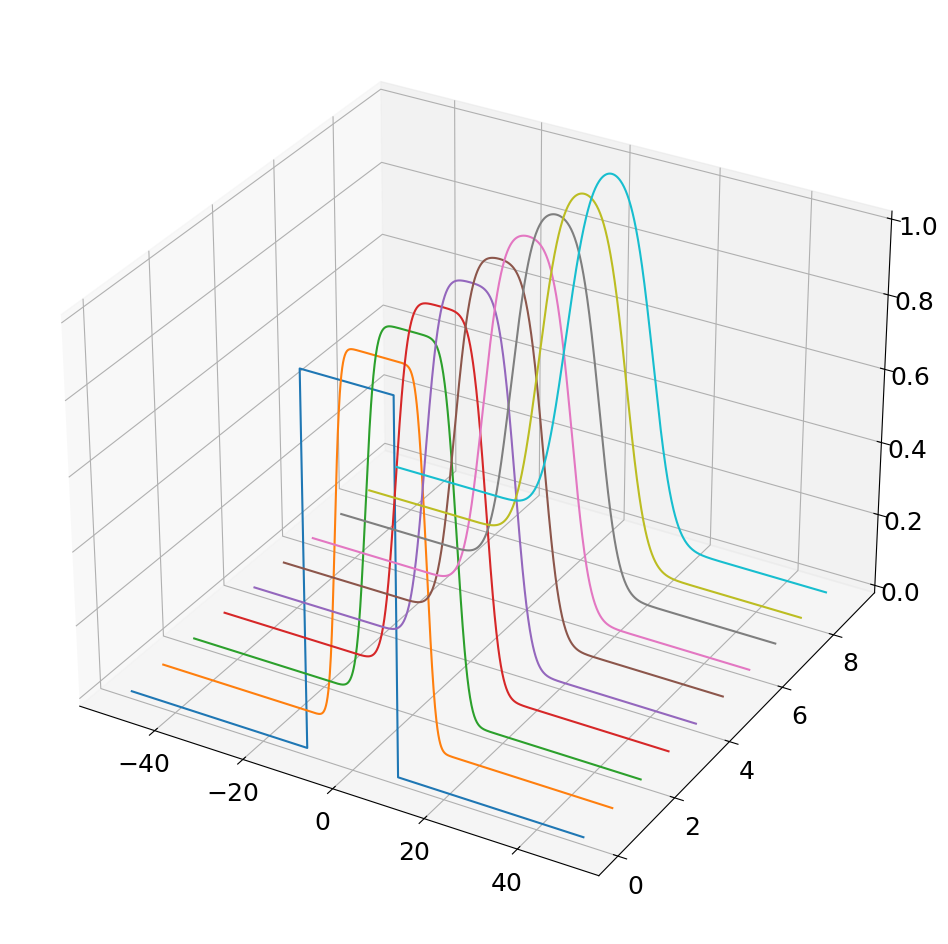

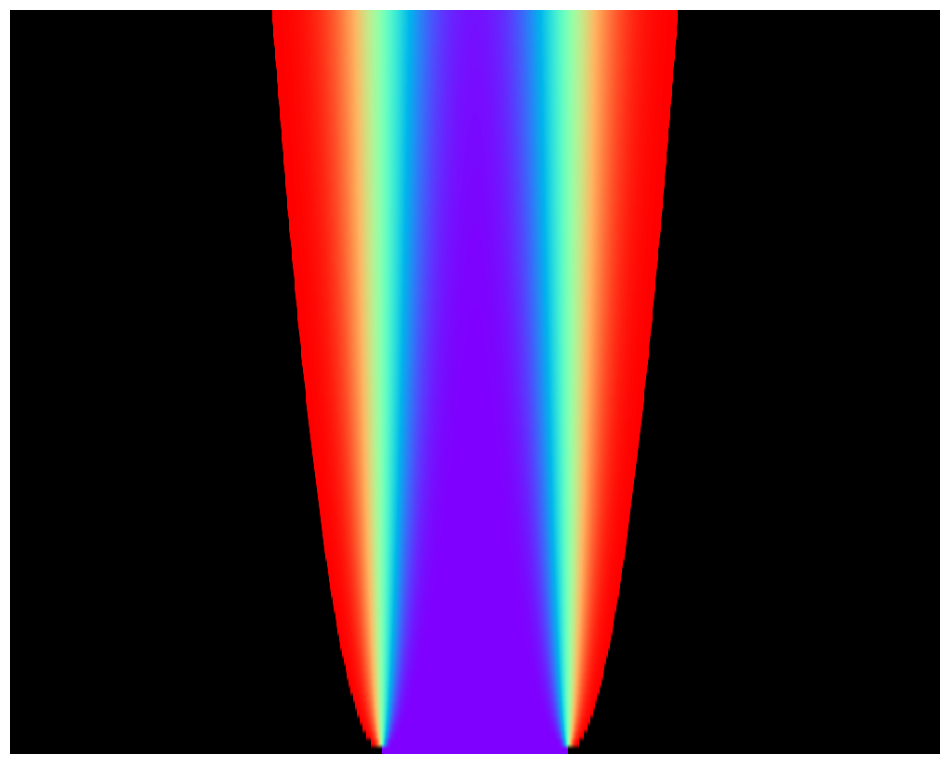

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.integrate import solve_ivp
from mpl_toolkits.mplot3d import axes3d
plt.rcParams['figure.figsize'] = [12, 12]
plt.rcParams.update({'font.size': 18})

a = 1   # Thermal diffusivity constant
L = 100  # Length of domain
N = 1000 # Number of discretization points
dx = L/N
x = np.arange(-L/2,L/2,dx) # Define x domain

# Define discrete wavenumbers
kappa = 2*np.pi*np.fft.fftfreq(N, d=dx)

# Initial condition
u0 = np.zeros_like(x)
u0[int((L/2 - L/10)/dx):int((L/2 + L/10)/dx)] = 1
u0hat = np.fft.fft(u0)

# SciPy's solve_ivp doesn't play well with complex numbers, so we recast 
# the state u0hat from an N-element complex vector to a 2N-element real vector
u0hat_ri = np.concatenate((u0hat.real,u0hat.imag))

# Simulate in Fourier frequency domain
# tmax scales as 1/a^2 so the diffusion looks the same for any 'a'
# (baseline: a=1 \u2192 tmax=10)
n_steps = 100
tmax = 10 / a**2
dt = tmax / n_steps
t = np.arange(0, tmax, dt)

# Note: solve_ivp expects f(t, y, ...) — t comes FIRST, unlike odeint's f(y, t, ...)
def rhsHeat(t, uhat_ri, kappa, a):
    uhat = uhat_ri[:N] + (1j) * uhat_ri[N:]
    d_uhat = -a**2 * (np.power(kappa,2)) * uhat
    d_uhat_ri = np.concatenate((d_uhat.real,d_uhat.imag)).astype('float64')
    return d_uhat_ri

# solve_ivp returns sol.y with shape (2N, len(t)), so we transpose to get (len(t), 2N)
sol = solve_ivp(rhsHeat, [t[0], t[-1]], u0hat_ri, t_eval=t, args=(kappa, a))
uhat_ri = sol.y.T

uhat = uhat_ri[:,:N] + (1j) * uhat_ri[:,N:]

u = np.zeros_like(uhat)

for k in range(len(t)):
    u[k,:] = np.fft.ifft(uhat[k,:])

u = u.real    

# Waterfall plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

u_plot = u[0:-1:10,:]
for j in range(u_plot.shape[0]):
    ys = j*np.ones(u_plot.shape[1])
    ax.plot(x,ys,u_plot[j,:])
    
# Image plot \u2014 custom colormap: black at 0, then rainbow_r (red \u2192 violet)
rainbow_r = plt.cm.rainbow_r
colors = [(0, 0, 0)] + [rainbow_r(i) for i in np.linspace(0, 1, 255)]
custom_cmap = mcolors.LinearSegmentedColormap.from_list('black_rainbow_r', colors, N=256)

plt.figure()
plt.imshow(np.flipud(u), aspect=8, cmap=custom_cmap)
plt.axis('off')
plt.show()

## Legacy: odeint version

The cell below is the original `odeint`-based implementation. Key differences from the `solve_ivp` version above:

- **RHS signature**: `f(y, t, ...)` instead of `f(t, y, ...)`
- **Call**: `odeint(f, y0, t, args=(...))` — no need for `t_eval` or time span
- **Output**: directly `(len(t), 2N)` — no transpose needed

Run **either** this cell or the `solve_ivp` cell above (not both), since they both write to the same variables.

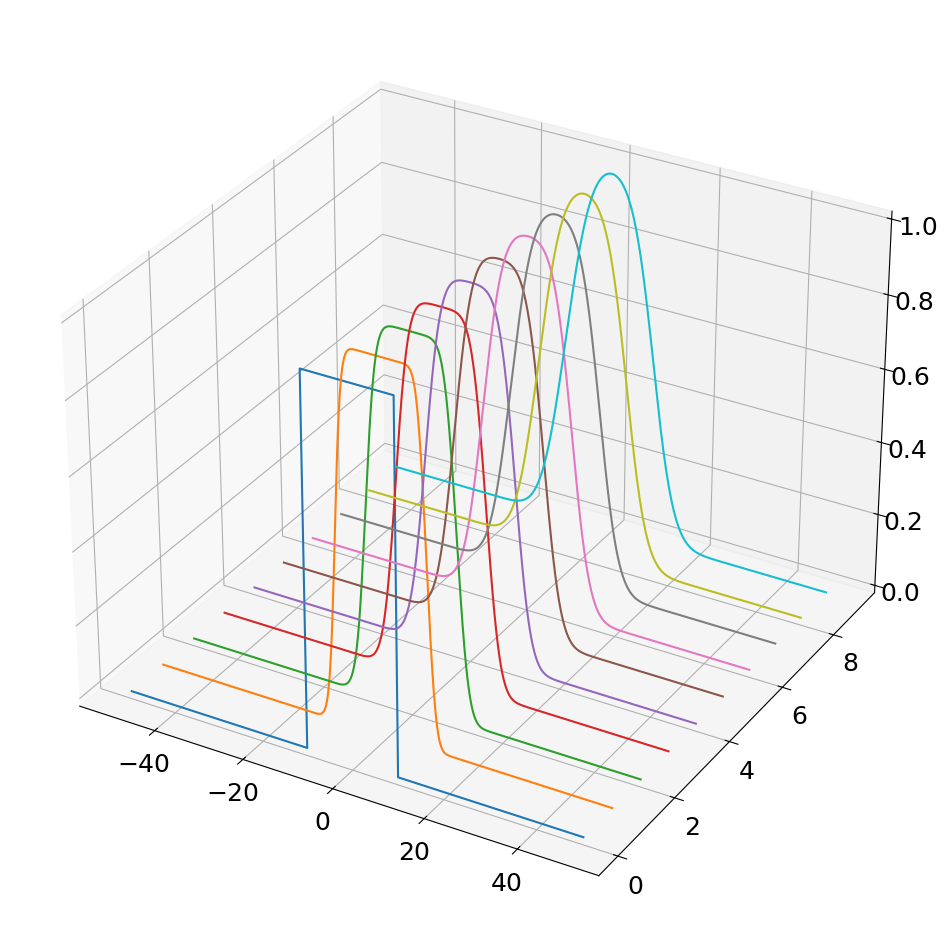

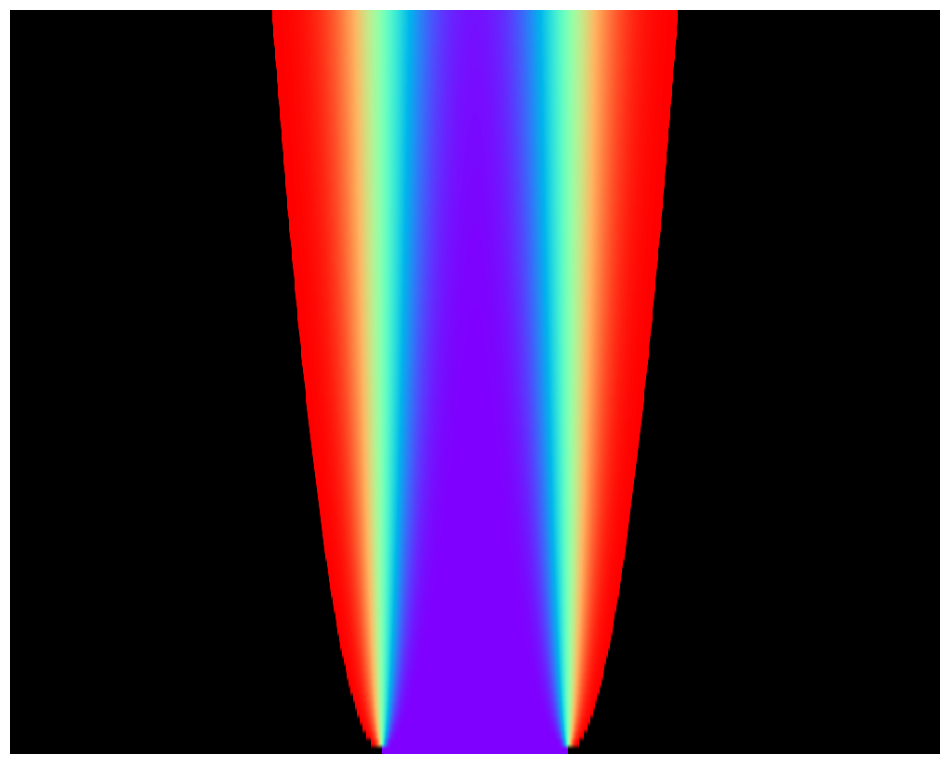

In [6]:
## odeint version (legacy — deprecated in favor of solve_ivp)
from scipy.integrate import odeint

# Note: odeint RHS signature is f(y, t, ...) — y comes first
def rhsHeat_odeint(uhat_ri, t, kappa, a):
    uhat = uhat_ri[:N] + (1j) * uhat_ri[N:]
    d_uhat = -a**2 * (np.power(kappa, 2)) * uhat
    d_uhat_ri = np.concatenate((d_uhat.real, d_uhat.imag)).astype('float64')
    return d_uhat_ri

uhat_ri = odeint(rhsHeat_odeint, u0hat_ri, t, args=(kappa, a))
# odeint output is already (len(t), 2N) — no transpose needed

uhat = uhat_ri[:,:N] + (1j) * uhat_ri[:,N:]

u = np.zeros_like(uhat)
for k in range(len(t)):
    u[k,:] = np.fft.ifft(uhat[k,:])
u = u.real

# Waterfall plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
u_plot = u[0:-1:10,:]
for j in range(u_plot.shape[0]):
    ys = j*np.ones(u_plot.shape[1])
    ax.plot(x, ys, u_plot[j,:])

# Image plot
rainbow_r = plt.cm.rainbow_r
colors = [(0, 0, 0)] + [rainbow_r(i) for i in np.linspace(0, 1, 255)]
custom_cmap = mcolors.LinearSegmentedColormap.from_list('black_rainbow_r', colors, N=256)

plt.figure()
plt.imshow(np.flipud(u), aspect=8, cmap=custom_cmap)
plt.axis('off')
plt.show()

## Note: `solve_ivp` vs `odeint`

This notebook replaces `odeint` with `solve_ivp` from `scipy.integrate`. Key differences:

| | `odeint` (legacy) | `solve_ivp` (modern) |
|---|---|---|
| **Import** | `from scipy.integrate import odeint` | `from scipy.integrate import solve_ivp` |
| **RHS signature** | `f(y, t, ...)` | `f(t, y, ...)` — **t comes first** |
| **Call** | `odeint(f, y0, t, args=(...))` | `solve_ivp(f, [t0, tf], y0, t_eval=t, args=(...))` |
| **Output shape** | `(len(t), N)` — rows are time steps | `sol.y` has shape `(N, len(t))` — **columns** are time steps |
| **Transpose needed** | No | Yes: `sol.y.T` to match odeint layout |
| **Default method** | LSODA (Adams/BDF auto-switch) | RK45 (explicit Runge-Kutta) |
| **Status** | Deprecated | Recommended replacement |

### What changed in the code

1. `def rhsHeat(uhat_ri, t, ...)` → `def rhsHeat(t, uhat_ri, ...)` — swapped first two args
2. `odeint(rhsHeat, u0hat_ri, t, args=(...))` → `solve_ivp(rhsHeat, [t[0], t[-1]], u0hat_ri, t_eval=t, args=(...))`
3. `uhat_ri = sol.y.T` — transpose because `solve_ivp` returns states as columns, not rows

## Note: Understanding the Plots

### Waterfall Plot (3D)

The waterfall plot shows the evolution of the temperature distribution $u(x, t)$ over time. Each curve is the spatial profile $u(x)$ at a different time step (every 10th step is plotted to avoid clutter):

- **x-axis**: spatial position $x \in [-L/2, L/2)$
- **y-axis**: time index (increasing into the plot)
- **z-axis**: temperature $u(x, t)$

At $t = 0$, the profile is a sharp rectangular pulse (hat function) centered at $x = 0$. As time progresses, the pulse **spreads out and flattens** — this is the hallmark of heat diffusion. Higher Fourier modes (sharp features) decay faster ($\propto e^{-a^2 \kappa^2 t}$), so the solution smooths out over time and approaches a uniform temperature.

### Image Plot (Heatmap)

The image plot (`imshow`) displays the same solution $u(x, t)$ as a 2D heatmap:

- **horizontal axis**: spatial position (N = 1000 points)
- **vertical axis**: time (flipped so $t = 0$ is at the **bottom** and later times are at the top)
- **color**: uses a custom colormap based on **rainbow_r**, matching the electromagnetic spectrum:
  - **Black** = zero temperature ($u = 0$) — no thermal energy
  - **Red** = low temperature — like infrared (low energy)
  - **Green/yellow** = intermediate temperature
  - **Violet/blue** = highest temperature (hottest, $u \approx 1$) — like ultraviolet (high energy)

The bright **violet** vertical stripe at the center corresponds to the initial rectangular pulse (the hot region). The surrounding **black** represents the cold ($u = 0$) background. As you move upward (forward in time), the violet stripe **widens and shifts toward green**, showing the heat spreading from the hot region into the cooler surroundings while the peak temperature drops.

In [7]:
print(f"x:         {x.shape}  \u2014 N={N} spatial grid points over domain [-L/2, L/2)")
print(f"kappa:     {kappa.shape}  \u2014 one wavenumber per spatial point (N discrete frequencies)")
print(f"u0:        {u0.shape}  \u2014 initial condition at N spatial points")
print(f"u0hat:     {u0hat.shape}  \u2014 FFT of u0, N complex Fourier coefficients")
print(f"u0hat_ri:  {u0hat_ri.shape}  \u2014 real/imag parts concatenated (2N) so solve_ivp can handle it")
print(f"t:         {t.shape}  \u2014 {len(t)} time steps from 0 to {t[-1]:.1f} with dt={dt}")
print(f"sol.y:     {sol.y.shape}  \u2014 solve_ivp raw output: 2N state variables x {sol.y.shape[1]} time steps")
print(f"uhat_ri:   {uhat_ri.shape}  \u2014 transposed: {len(t)} time steps x 2N real values")
print(f"uhat:      {uhat.shape}  \u2014 reassembled complex coefficients: {len(t)} time steps x N modes")
print(f"u:         {u.shape}  \u2014 physical solution after iFFT: {len(t)} time steps x N spatial points")

x:         (1000,)  — N=1000 spatial grid points over domain [-L/2, L/2)
kappa:     (1000,)  — one wavenumber per spatial point (N discrete frequencies)
u0:        (1000,)  — initial condition at N spatial points
u0hat:     (1000,)  — FFT of u0, N complex Fourier coefficients
u0hat_ri:  (2000,)  — real/imag parts concatenated (2N) so solve_ivp can handle it
t:         (100,)  — 100 time steps from 0 to 9.9 with dt=0.1
sol.y:     (2000, 100)  — solve_ivp raw output: 2N state variables x 100 time steps
uhat_ri:   (100, 2000)  — transposed: 100 time steps x 2N real values
uhat:      (100, 1000)  — reassembled complex coefficients: 100 time steps x N modes
u:         (100, 1000)  — physical solution after iFFT: 100 time steps x N spatial points


## Note: Understanding the Discrete Wavenumbers

`np.fft.fftfreq(N, d=dx)` returns the discrete frequencies for an N-point DFT with sample spacing `dx`, in cycles per unit length:

$$f = \left[0,\; \frac{1}{N \cdot dx},\; \frac{2}{N \cdot dx},\; \ldots\right]$$

(with negative frequencies in the second half of the array).

Multiplying by $2\pi$ converts ordinary frequencies ($f$) to **angular wavenumbers** ($\kappa$):

$$\kappa = 2\pi f = \frac{2\pi k}{N \cdot dx} = \frac{2\pi k}{L}$$

This is needed because the heat equation in Fourier space is:

$$\frac{d\hat{u}}{dt} = -a^2 \kappa^2 \hat{u}$$

where $\kappa$ must be in **radians per unit length**. The resulting `kappa` array has one wavenumber per Fourier coefficient, so `rhsHeat` can compute the spectral derivative by simply multiplying $-a^2 \kappa^2$ element-wise with the Fourier coefficients.

## Note: FFT Coefficient Ordering

`np.fft.fft` returns the N Fourier coefficients in a specific order — **not** the "natural" $-N/2$ to $N/2$ order:

| Index | Wavenumber | Meaning |
|---|---|---|
| `0` | $\kappa_0 = 0$ | DC component (mean value) |
| `1` | $\kappa_1 = 2\pi/L$ | Lowest positive frequency |
| `2` | $\kappa_2 = 4\pi/L$ | Next positive frequency |
| $\vdots$ | $\vdots$ | $\vdots$ |
| `N/2 - 1` | $\kappa_{N/2-1}$ | Highest positive frequency |
| `N/2` | $\pm\kappa_{N/2}$ | Nyquist frequency |
| `N/2 + 1` | $\kappa_{-(N/2-1)}$ | Highest negative frequency |
| $\vdots$ | $\vdots$ | $\vdots$ |
| `N - 1` | $\kappa_{-1} = -2\pi/L$ | Lowest negative frequency |

The first half contains **positive frequencies** (low to high), then the second half contains **negative frequencies** (high to low).

This is the same order that `np.fft.fftfreq` returns, which is why `kappa` and `uhat` are aligned element-wise — index `k` in `uhat` corresponds to wavenumber `kappa[k]`. The element-wise multiplication `-a**2 * kappa**2 * uhat` in `rhsHeat` works precisely because both arrays share this ordering.

To get the "natural" order ($-N/2$ to $N/2-1$), use `np.fft.fftshift`.

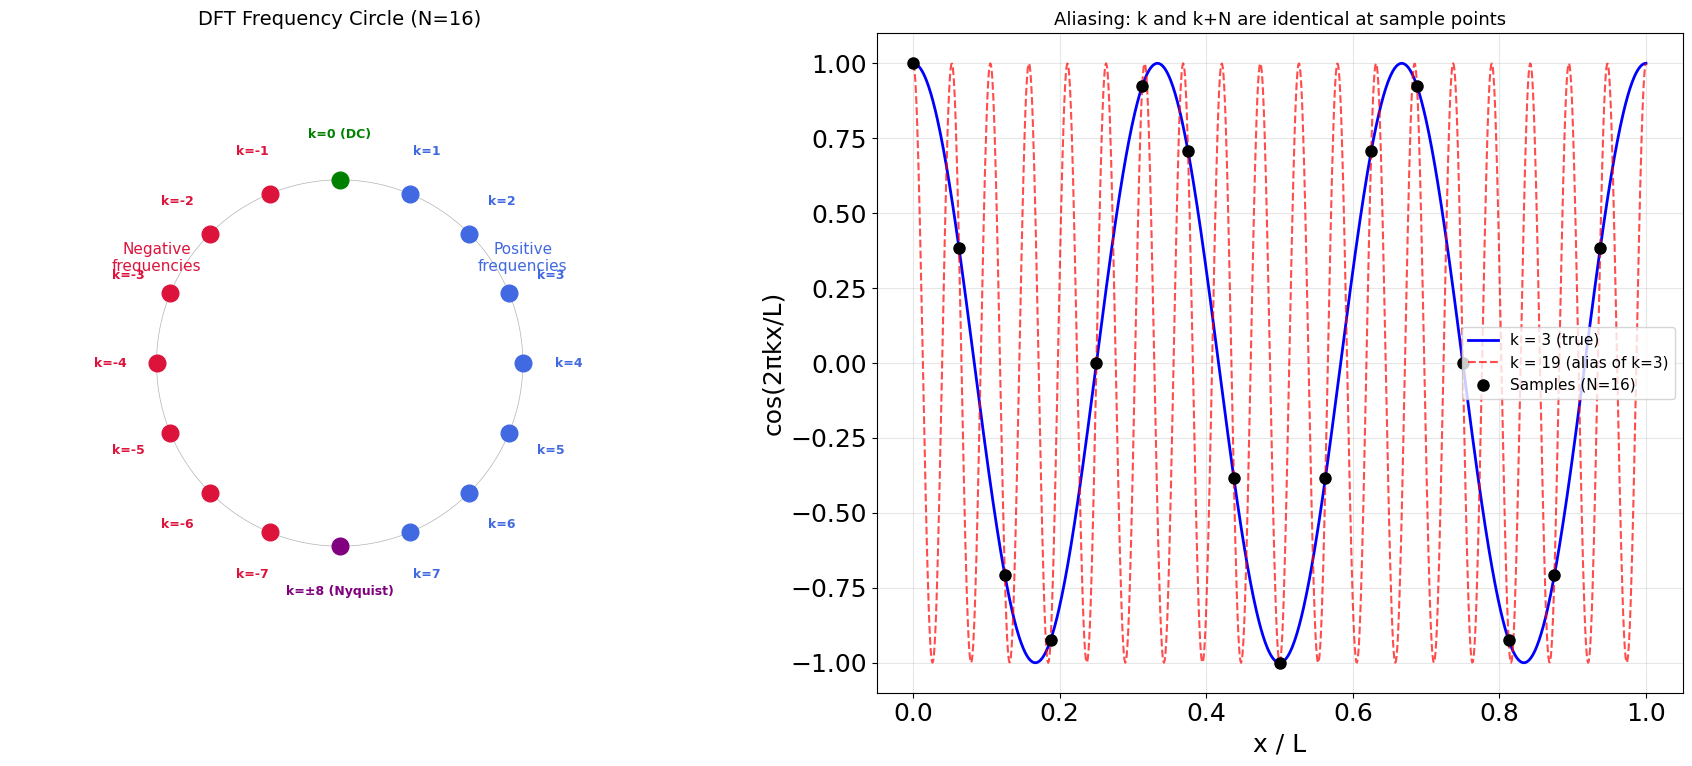

In [8]:
# Visualize the frequency circle (Nyquist / modular structure of the DFT)
# Using a small N for clarity
N_demo = 16
freqs = np.fft.fftfreq(N_demo)  # normalized frequencies in [-0.5, 0.5)

# Place each DFT index on a circle: index k maps to angle -2*pi*k/N (clockwise from top)
angles = -2 * np.pi * np.arange(N_demo) / N_demo + np.pi / 2  # start at top (DC)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- Left: The frequency circle ---
ax1 = axes[0]
ax1.set_aspect('equal')
ax1.set_xlim(-1.8, 1.8)
ax1.set_ylim(-1.8, 1.8)

# Draw the circle
theta_circle = np.linspace(0, 2 * np.pi, 200)
ax1.plot(np.cos(theta_circle), np.sin(theta_circle), 'k-', linewidth=0.5, alpha=0.3)

# Color: positive freqs = blue, negative = red, DC = green, Nyquist = purple
for i in range(N_demo):
    cx, cy = np.cos(angles[i]), np.sin(angles[i])
    freq_index = i if i <= N_demo // 2 else i - N_demo  # "true" frequency index

    if i == 0:
        color, label = 'green', f'k=0 (DC)'
    elif i == N_demo // 2:
        color, label = 'purple', f'k=±{N_demo//2} (Nyquist)'
    elif i < N_demo // 2:
        color, label = 'royalblue', f'k={freq_index}'
    else:
        color, label = 'crimson', f'k={freq_index}'

    ax1.plot(cx, cy, 'o', color=color, markersize=12, zorder=5)
    # Label outside the circle
    ax1.annotate(label, (cx * 1.25, cy * 1.25), ha='center', va='center', fontsize=9,
                 fontweight='bold', color=color)

ax1.set_title(f'DFT Frequency Circle (N={N_demo})', fontsize=14)
ax1.annotate('Positive\nfrequencies', xy=(1.0, 0.5), fontsize=11, color='royalblue', ha='center')
ax1.annotate('Negative\nfrequencies', xy=(-1.0, 0.5), fontsize=11, color='crimson', ha='center')
ax1.axis('off')

# --- Right: Aliasing demo ---
ax2 = axes[1]
n_points = 16
x_fine = np.linspace(0, 1, 1000)
x_samples = np.linspace(0, 1, n_points, endpoint=False)

# A low frequency (k=3) and its alias (k=3-16=-13, or equivalently k=3+16=19 looks the same)
k_low = 3
k_alias = k_low + n_points  # k=19 aliases to k=3

ax2.plot(x_fine, np.cos(2 * np.pi * k_low * x_fine), 'b-', linewidth=2,
         label=f'k = {k_low} (true)')
ax2.plot(x_fine, np.cos(2 * np.pi * k_alias * x_fine), 'r--', linewidth=1.5, alpha=0.7,
         label=f'k = {k_alias} (alias of k={k_low})')
ax2.plot(x_samples, np.cos(2 * np.pi * k_low * x_samples), 'ko', markersize=8, zorder=5,
         label=f'Samples (N={n_points})')

ax2.set_xlabel('x / L')
ax2.set_ylabel('cos(2πkx/L)')
ax2.set_title('Aliasing: k and k+N are identical at sample points', fontsize=13)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Note: The Frequency Circle and Aliasing

### The circular / modulo structure of the DFT

The N discrete frequencies don't live on a line — they live on a **circle**. The fundamental identity is:

$$e^{i2\pi(k+N)n/N} = e^{i2\pi kn/N}$$

Frequency $k$ and frequency $k + N$ produce **identical samples** at the N grid points. So frequency is only meaningful **mod N** — it wraps around a circle of circumference N.

- **Top** ($k=0$): DC component (zero frequency)
- **Right half** ($k=1$ to $N/2-1$): positive frequencies, shown in blue
- **Bottom** ($k=N/2$): Nyquist frequency — where positive and negative meet
- **Left half** ($k=N/2+1$ to $N-1$, equivalently $k=-N/2+1$ to $-1$): negative frequencies, shown in red

### Aliasing

The right plot shows why frequencies above Nyquist are indistinguishable: $\cos(2\pi k x/L)$ and $\cos(2\pi (k+N) x/L)$ pass through the **exact same sample points**. With only N samples, you literally cannot tell them apart. That's why N samples yield at most N independent frequencies.

## Note: Why Only N Discrete Frequencies?

In the continuous Fourier series, we sum over infinitely many modes $k \in (-\infty, +\infty)$. So why does `np.fft.fft` give us only N coefficients?

### 1. Discrete sampling limits the frequencies (Nyquist theorem)

With N spatial points spaced by $dx$, the highest resolvable wavenumber is the **Nyquist frequency**:

$$\kappa_{\max} = \frac{\pi}{dx}$$

Any frequency above this is indistinguishable from a lower one (**aliasing**). So the discrete grid naturally caps us at N distinct wavenumbers:

$$\kappa_k = \frac{2\pi k}{L}, \quad k = -N/2, \ldots, N/2 - 1$$

### 2. The DFT is a bijection: N points $\leftrightarrow$ N coefficients

The DFT maps N spatial samples to exactly N Fourier coefficients — and back, losslessly:

$$N \text{ spatial points} \;\xleftrightarrow{\text{FFT / iFFT}}\; N \text{ frequency coefficients}$$

The "missing" high-frequency modes ($|k| > N/2$) were never captured by the grid. Resolving them would require finer sampling (smaller $dx$, larger $N$).

### Summary

| Continuous | Discrete (our code) |
|---|---|
| Infinite frequencies $k \in (-\infty, +\infty)$ | N frequencies $k \in [-N/2, N/2)$ |
| Requires infinite spatial resolution | Limited by $dx = L/N$ |
| Perfect representation | Exact up to Nyquist, aliases above |

With $N = 1000$ and $dx = 0.1$, we resolve wavenumbers up to $\kappa_{\max} = \pi/0.1 \approx 31.4$ rad/unit length — more than enough for the smooth shapes the heat equation produces.

## Note: Understanding the Initial Condition

- **`u0 = np.zeros_like(x)`** — creates an array of zeros with the same shape as `x` (1000 points). The initial temperature is zero everywhere.

- **`u0[int((L/2 - L/10)/dx):int((L/2 + L/10)/dx)] = 1`** — sets a rectangular pulse (hat function) centered at the middle of the domain:
  - `L/2 - L/10 = 50 - 10 = 40`, divided by `dx = 0.1` → index **400**
  - `L/2 + L/10 = 50 + 10 = 60`, divided by `dx = 0.1` → index **600**
  - So `u0[400:600] = 1` — a block of 1s spanning $x \in [-10, 10]$ (the central 20% of the domain), with 0 elsewhere.

- **`u0hat = np.fft.fft(u0)`** — computes the discrete Fourier transform of the initial condition, moving it into frequency space. This is the starting state for the ODE solver, which evolves each Fourier mode independently according to $\frac{d\hat{u}}{dt} = -a^2 \kappa^2 \hat{u}$.

## Note: The Real/Imaginary Split and ODE Integration

### Why split into real and imaginary parts?

SciPy's `solve_ivp` only works with **real-valued** state vectors — it cannot integrate complex ODEs directly. Since the Fourier coefficients `u0hat` are complex, we split them into a 2N-element real vector:

$$\texttt{u0hat\_ri} = [\underbrace{\text{Re}(\hat{u}_0), \ldots, \text{Re}(\hat{u}_{N-1})}_{N \text{ real parts}},\; \underbrace{\text{Im}(\hat{u}_0), \ldots, \text{Im}(\hat{u}_{N-1})}_{N \text{ imaginary parts}}]$$

This is done with: `u0hat_ri = np.concatenate((u0hat.real, u0hat.imag))`

### How `rhsHeat` works

This function computes $d\hat{u}/dt$ for the ODE solver:

1. **Reassemble complex:** `uhat = uhat_ri[:N] + (1j) * uhat_ri[N:]` — reconstructs the N complex Fourier coefficients from the 2N real vector.

2. **Apply the heat equation:** `d_uhat = -a**2 * kappa**2 * uhat` — this is the spectral form of the heat equation. The PDE $\frac{\partial u}{\partial t} = a^2 \frac{\partial^2 u}{\partial x^2}$ becomes, in Fourier space, an ODE for each mode: $\frac{d\hat{u}_k}{dt} = -a^2 \kappa_k^2 \hat{u}_k$

3. **Split back to real:** `np.concatenate((d_uhat.real, d_uhat.imag))` — returns the derivative in the 2N real format that `solve_ivp` expects.

### What `solve_ivp` returns

`solve_ivp(rhsHeat, [t[0], t[-1]], u0hat_ri, t_eval=t, args=(kappa,a))` numerically integrates the ODE forward through all time points in `t`. It returns a `Bunch` object with `sol.y` of shape `(2N, len(t))` — **columns** are time steps (unlike `odeint` which uses rows).

The code then transposes, reassembles, and inverse-transforms:

- `uhat_ri = sol.y.T` — transpose to shape `(len(t), 2N)` so rows are time steps
- `uhat = uhat_ri[:,:N] + (1j) * uhat_ri[:,N:]` — reconstruct complex coefficients at all times, shape `(100, 1000)`
- `u[k,:] = np.fft.ifft(uhat[k,:])` — inverse FFT each row back to physical space

### Division of labor

- **FFT** handles space: converts $\frac{\partial^2}{\partial x^2}$ into multiplication by $-\kappa^2$
- **solve_ivp** handles time: numerically integrates $\frac{d\hat{u}}{dt}$ forward through the time points